<a href="https://colab.research.google.com/github/xudavid715-cloud/Problem-set-2/blob/main/Econ_3916_PS2_(3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS2 — The Survey That Wasn't Random

**ECON 3916 · Applied Data Analytics** · Topics 5-8 · 100 points · your role: Data Analyst, Growth team

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is data analyst's audience, not a grader with a kernel.

AI is not allowed in Phases 1–3. Generative AI is prohibited in Phases 1 through 3. You write the simulations, the bootstrap loop and the tests yourself. AI is authorised and required in Phase 4. If you cannot explain a line you submitted, you cannot submit it.


## Setup

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import expit      # logistic(z) = 1 / (1 + exp(-z))

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

# scipy.stats.bootstrap gets its OWN seeded generator. Different scipy versions consume
# random numbers differently; keeping scipy off the main stream means every number from
# my own code reruns identically on any machine.
rng_scipy = np.random.default_rng(2026)

def scipy_bootstrap(x, stat, method, B=2000):
    """scipy.stats.bootstrap; scipy >= 1.15 calls the seed argument `rng`, older versions `random_state`."""
    # vectorized: np.mean / np.median take axis=; batch keeps the BCa jackknife from building an n x n array
    kw = dict(n_resamples=B, method=method, confidence_level=0.95, vectorized=True, batch=200)
    try:
        return stats.bootstrap((x,), stat, rng=rng_scipy, **kw)
    except TypeError:
        return stats.bootstrap((x,), stat, random_state=rng_scipy, **kw)

## Phase 1: Simulate the Population You Cannot See (30 pts)

### Step 1.1: Build a world with a known answer (15 pts)

In [12]:
# Parameters the brief fixes (Step 1.1). Keep them here so the grader can rerun you.
N_USERS = 50_000
BASE_BEFORE, BASE_AFTER = 3.432, 3.532      # true means 3.30 and 3.40

def simulate_population(base, n=N_USERS, rng=rng):
    """Return a DataFrame with engagement_minutes, engagement_z, had_support_ticket,
    latent s and the reported 1–5 satisfaction score."""
    engagement_minutes = rng.lognormal(mean=3.5, sigma=0.6, size=n)    # params of the underlying normal
    engagement_z = (engagement_minutes - engagement_minutes.mean()) / engagement_minutes.std()
    had_support_ticket = rng.binomial(1, 0.22, size=n)                 # Bernoulli(0.22)
    s = base + 0.35 * engagement_z - 0.60 * had_support_ticket + rng.normal(0, 0.75, size=n)
    score = np.clip(np.rint(s), 1, 5).astype(int)                      # five-point scale
    return pd.DataFrame({'engagement_minutes': engagement_minutes,
                         'engagement_z': engagement_z,
                         'had_support_ticket': had_support_ticket,
                         's': s,
                         'score': score})

pre  = simulate_population(BASE_BEFORE)
post = simulate_population(BASE_AFTER)

# ---- The truth, on file ----
TRUE_S_PRE,     TRUE_S_POST     = pre['s'].mean(),     post['s'].mean()      # latent satisfaction
TRUE_SCORE_PRE, TRUE_SCORE_POST = pre['score'].mean(), post['score'].mean()  # what a perfect census would report
TRUE_GAP       = TRUE_SCORE_POST - TRUE_SCORE_PRE

truth = pd.DataFrame({
    'design value':            [3.30, 3.40, 0.10],
    'latent s (simulated)':    [TRUE_S_PRE, TRUE_S_POST, TRUE_S_POST - TRUE_S_PRE],
    'reported 1-5 (simulated)':[TRUE_SCORE_PRE, TRUE_SCORE_POST, TRUE_GAP]},
    index=['pre-redesign', 'post-redesign', 'improvement'])
print(truth.round(3))

# The covariates really drive satisfaction:
print('\ncorr(engagement_z, s) pre:', round(np.corrcoef(pre.engagement_z, pre.s)[0, 1], 3))
print('mean s | ticket=1 minus mean s | ticket=0 (pre):',
      round(pre.groupby('had_support_ticket').s.mean().diff().iloc[-1], 3))
print('\nshare of users at each score, full pre-redesign population:')
print(pre.score.value_counts(normalize=True).sort_index().round(3).to_string())

               design value  latent s (simulated)  reported 1-5 (simulated)
pre-redesign            3.3                 3.299                     3.290
post-redesign           3.4                 3.399                     3.386
improvement             0.1                 0.100                     0.096

corr(engagement_z, s) pre: 0.412
mean s | ticket=1 minus mean s | ticket=0 (pre): -0.597

share of users at each score, full pre-redesign population:
score
1    0.018
2    0.159
3    0.421
4    0.319
5    0.083


**What I built.** Two independent populations of 50,000 users (before and after the redesign), drawn from one generator seeded at 42, exactly to the brief: `engagement_minutes` is lognormal with underlying-normal mean 3.5 and sd 0.6, z-scored into `engagement_z`; `had_support_ticket` is Bernoulli(0.22); latent satisfaction is `s = base + 0.35·engagement_z − 0.60·had_support_ticket + N(0, 0.75²)`; the reported score is `s` rounded and clipped to 1–5.

**The truth, on file.**

| | design | latent `s` (simulated) | reported 1–5 score (simulated census) |
|---|---|---|---|
| Pre-redesign | 3.30 | 3.299 | 3.290 |
| Post-redesign | 3.40 | 3.399 | 3.386 |
| True improvement | 0.10 | 0.100 | 0.096 |

The base values work because E[s] = base − 0.60 × 0.22 = base − 0.132 (engagement_z and the noise have mean zero), so 3.432 → 3.30 and 3.532 → 3.40. The reported-score means sit about 0.01 below the latent means because clipping at 1 and 5 and rounding are not perfectly symmetric. Since the survey asks for the 1–5 score, the census means of the **reported** score (3.290 and 3.386, a true improvement of 0.096) are the benchmark I hold every estimate to below; they round to the 3.30 / 3.40 / 0.10 the brief fixes.

Both covariates genuinely drive satisfaction: corr(engagement_z, s) = 0.41, and users with a support ticket are 0.60 points less satisfied on average. That matters later: they also drive who responds, which is what makes them plausible (but, as Phase 4 shows, insufficient) adjustment variables.

### Step 1.2: Impose the response mechanism (15 pts)

               response rate  respondents  observed mean  true mean (census)
pre-redesign           0.275        13768          3.600               3.290
post-redesign          0.152         7597          4.304               3.386

apparent gap 0.704  vs  true gap 0.096  (design 0.10)
CHECKPOINT PASSED

response rate by the score a user WOULD give:
         pre   post
score              
1      0.105  0.000
2      0.161  0.005
3      0.229  0.041
4      0.339  0.202
5      0.522  0.651


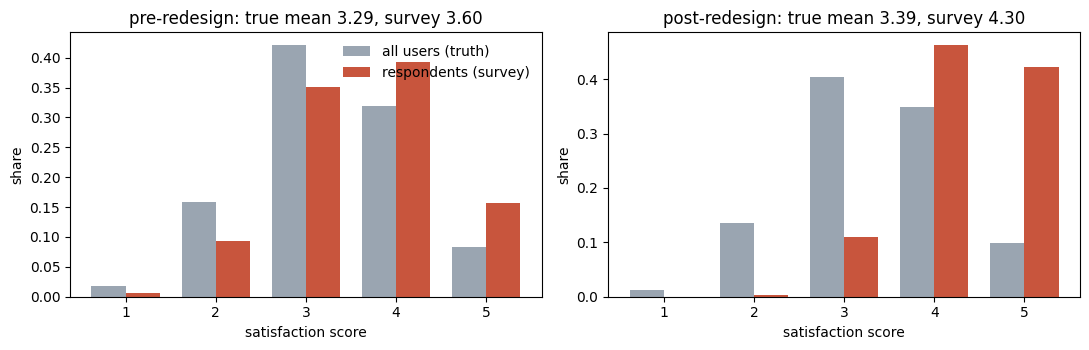

In [13]:
A_PRE,  B_PRE  = -1.00, 0.45
A_POST, B_POST = -2.75, 2.00

def respond(df, a, b, rng=rng):
    """Who answers the survey: P(respond) = logistic(a + b*(s - 3.3) + 0.30*engagement_z
    - 0.25*had_support_ticket); a user answers when a uniform draw is below it."""
    out = df.copy()
    out['p_respond'] = expit(a + b * (out['s'] - 3.3) + 0.30 * out['engagement_z']
                             - 0.25 * out['had_support_ticket'])
    out['responded'] = rng.uniform(size=len(out)) < out['p_respond']
    return out

pre  = respond(pre,  A_PRE,  B_PRE)
post = respond(post, A_POST, B_POST)

obs_pre  = pre.loc[pre.responded,  'score'].to_numpy()
obs_post = post.loc[post.responded, 'score'].to_numpy()
OBS_GAP  = obs_post.mean() - obs_pre.mean()

summary = pd.DataFrame({
    'response rate':      [pre.responded.mean(), post.responded.mean()],
    'respondents':        [len(obs_pre), len(obs_post)],
    'observed mean':      [obs_pre.mean(), obs_post.mean()],
    'true mean (census)': [TRUE_SCORE_PRE, TRUE_SCORE_POST]},
    index=['pre-redesign', 'post-redesign'])
print(summary.round(3))
print(f'\napparent gap {OBS_GAP:.3f}  vs  true gap {TRUE_GAP:.3f}  (design 0.10)')

# ---- checkpoint ----
assert 3.55 <= obs_pre.mean()  <= 3.65, 'pre checkpoint failed'
assert 4.25 <= obs_post.mean() <= 4.35, 'post checkpoint failed'
print('CHECKPOINT PASSED')

# who answers, by true satisfaction score
rates = pd.DataFrame({'pre': pre.groupby('score').responded.mean(),
                      'post': post.groupby('score').responded.mean()})
print('\nresponse rate by the score a user WOULD give:')
print(rates.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
w = 0.38
for k, (df, lab) in enumerate([(pre, 'pre-redesign'), (post, 'post-redesign')]):
    full = df.score.value_counts(normalize=True).sort_index()
    resp = df.loc[df.responded, 'score'].value_counts(normalize=True).reindex(range(1, 6), fill_value=0)
    ax[k].bar(full.index - w/2, full.values, w, label='all users (truth)', color='#9aa5b1')
    ax[k].bar(resp.index + w/2, resp.values, w, label='respondents (survey)', color='#c8553d')
    ax[k].set_title(f'{lab}: true mean {df.score.mean():.2f}, survey {df.loc[df.responded, "score"].mean():.2f}')
    ax[k].set_xlabel('satisfaction score'); ax[k].set_ylabel('share')
ax[0].legend(frameon=False)
plt.tight_layout(); plt.show()

> **🛑 Verification checkpoint.** You should get an observed pre-redesign mean of
> about **3.60** (accept 3.55 to 3.65) and an observed post-redesign mean of
> about **4.31** (accept 4.25 to 4.35) — an apparent gap of roughly **0.71**
> points out of a true improvement of **0.10**. Response rates should fall from
> roughly 27% to roughly 15%. If your numbers are outside those bands, your
> response function or your `base` values are wrong. **Do not proceed until it
> matches** — everything after this depends on reproducing the PM's slide.

**Checkpoint met.** Observed mean among respondents: **3.600** before (band 3.55–3.65) and **4.304** after (band 4.25–4.35), an apparent improvement of **0.704** points against a true improvement of **0.096**. Response rates fell from **27.5%** (13,768 respondents) to **15.2%** (7,597 respondents).

**Failure mode: non-response bias, a form of selection bias in which the sample selects itself on the outcome.** Whether a user answers depends on their own satisfaction (the `b·(s − 3.3)` term), so the data are *missing not at random*: respondents are systematically happier than users. The redesign made this far worse. Before, a user who would score 5 was about 5× as likely to answer as one who would score 1 (52% vs 10%). After, users who would score 1 essentially never answered (0.0%), those who would score 2 answered 0.5% of the time, and those who would score 5 answered 65% of the time (table above). The survey's 0.70 "improvement" is mostly a change in *who answered*, not in how users feel: about 0.61 of the 0.70 points is bias.

**Why a larger survey would not fix it.** A bigger sample reduces variance; it does nothing to bias, because the bias is a property of the response mechanism, not of the sample size. Invite twice as many users and you get twice as many of the same self-selected respondents, whose mean converges, ever more precisely, to E[score | responded] ≈ 4.30, not to E[score] = 3.39. Here the survey already went to all 50,000 users, so there is no larger survey to run: the problem is who answers, not how many. Step 3.2 shows this by simulation.

**Note the response rates:** the survey that produced the better number heard from *fewer* people (15% vs 27%). That is a warning sign in itself: the "improvement" arrived together with a collapse in response among exactly the users who would have pulled the mean down.

## Phase 2: Quantify What You Actually Know (35 pts)

### Step 2.1: Uncertainty without a formula (20 pts)

In [14]:
def bootstrap_by_hand(x, stat, B=2000, rng=rng):
    """Your own resampling loop; returns the B bootstrap statistics."""
    x = np.asarray(x)
    n = len(x)
    boot = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)      # draw n rows WITH replacement
        boot[b] = stat(x[idx])
    return boot

def percentile_ci(boot, alpha=0.05):
    return np.quantile(boot, [alpha / 2, 1 - alpha / 2])

def bca_ci(x, stat, boot, alpha=0.05):
    """BCa by hand: bias-correction z0 from the bootstrap draws, acceleration a from the jackknife."""
    x = np.asarray(x); n = len(x)
    theta = stat(x)
    prop_below = np.mean(boot < theta)
    if prop_below in (0.0, 1.0):          # every draw on one side of theta: z0 is infinite
        return np.array([np.nan, np.nan])
    z0 = stats.norm.ppf(prop_below)
    # jackknife: leave one observation out at a time
    jack = np.array([stat(np.delete(x, i)) for i in range(n)]) if n <= 20_000 else None
    d = jack.mean() - jack
    a = np.sum(d**3) / (6 * np.sum(d**2) ** 1.5) if np.sum(d**2) > 0 else 0.0
    z = stats.norm.ppf([alpha / 2, 1 - alpha / 2])
    adj = stats.norm.cdf(z0 + (z0 + z) / (1 - a * (z0 + z)))
    return np.quantile(boot, adj)

rows = []
boots = {}
for period, x in [('pre', obs_pre), ('post', obs_post)]:
    for name, stat in [('mean', np.mean), ('median', np.median)]:
        bt = bootstrap_by_hand(x, stat)
        boots[(period, name)] = bt
        pc = percentile_ci(bt)
        bc = bca_ci(x, stat, bt)
        rows.append([period, name, stat(x), bt.std(ddof=1), *pc, *bc])

hand = pd.DataFrame(rows, columns=['period', 'stat', 'estimate', 'boot SE',
                                   'pct lo', 'pct hi', 'BCa lo', 'BCa hi'])
bt = boots[('post', 'mean')]
z0_post = stats.norm.ppf(np.mean(bt < obs_post.mean()))
jk = (obs_post.sum() - obs_post) / (len(obs_post) - 1); d = jk.mean() - jk
a_post = np.sum(d**3) / (6 * np.sum(d**2) ** 1.5)
print(f'post mean BCa ingredients: z0 = {z0_post:.3f}, acceleration a = {a_post:.5f}')
print('BY HAND (B = 2000)')
print(hand.to_string(index=False, float_format='%.4f'))

post mean BCa ingredients: z0 = 0.010, acceleration a = -0.00102
BY HAND (B = 2000)
period   stat  estimate  boot SE  pct lo  pct hi  BCa lo  BCa hi
   pre   mean    3.5999   0.0076  3.5848  3.6150  3.5850  3.6151
   pre median    4.0000   0.0000  4.0000  4.0000     NaN     NaN
  post   mean    4.3041   0.0077  4.2891  4.3188  4.2891  4.3188
  post median    4.0000   0.0000  4.0000  4.0000     NaN     NaN


SCIPY stats.bootstrap (B = 2000)
period   stat  pct lo  pct hi  BCa lo  BCa hi  boot SE
   pre   mean  3.5852  3.6145  3.5854  3.6143   0.0073
   pre median  4.0000  4.0000     NaN     NaN   0.0000
  post   mean  4.2891  4.3208  4.2893  4.3200   0.0078
  post median  4.0000  4.0000     NaN     NaN   0.0000

hand minus scipy, means:
period  pct lo diff  pct hi diff  BCa lo diff  BCa hi diff  boot SE diff
   pre      -0.0004       0.0005      -0.0004       0.0008        0.0003
  post       0.0000      -0.0020      -0.0002      -0.0012       -0.0001
pre: t-interval 3.5852 to 3.6147
post: t-interval 4.2889 to 4.3193

what the median bootstrap distribution looks like (post): {4.0: 2000}


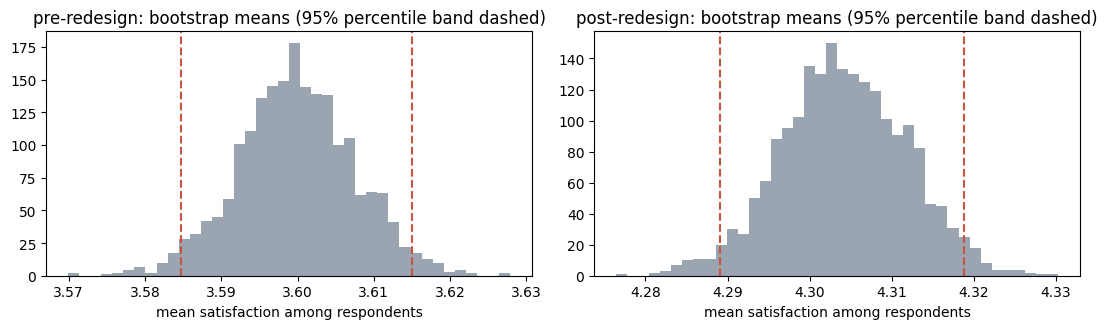

In [15]:
import warnings
rows = []
for period, x in [('pre', obs_pre), ('post', obs_post)]:
    for name, stat in [('mean', np.mean), ('median', np.median)]:
        out = [period, name]
        for method in ['percentile', 'BCa']:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')       # BCa on the median is degenerate (see text)
                res = scipy_bootstrap(x, stat, method)
            out += [res.confidence_interval.low, res.confidence_interval.high]
        out.append(res.standard_error)
        rows.append(out)

sp = pd.DataFrame(rows, columns=['period', 'stat', 'pct lo', 'pct hi', 'BCa lo', 'BCa hi', 'boot SE'])
print('SCIPY stats.bootstrap (B = 2000)')
print(sp.to_string(index=False, float_format='%.4f'))

# agreement check on the means (the medians are identical, degenerate intervals)
m = hand.merge(sp, on=['period', 'stat'], suffixes=('_hand', '_scipy'))
m = m[m.stat == 'mean']
for c in ['pct lo', 'pct hi', 'BCa lo', 'BCa hi', 'boot SE']:
    m[c + ' diff'] = m[c + '_hand'] - m[c + '_scipy']
print('\nhand minus scipy, means:')
print(m[['period'] + [c for c in m if c.endswith('diff')]].to_string(index=False, float_format='%.4f'))

# textbook t interval, for reference
for period, x in [('pre', obs_pre), ('post', obs_post)]:
    se = x.std(ddof=1) / np.sqrt(len(x))
    print(f'{period}: t-interval {x.mean() - 1.96*se:.4f} to {x.mean() + 1.96*se:.4f}')

print('\nwhat the median bootstrap distribution looks like (post):',
      pd.Series(boots[('post', 'median')]).value_counts().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for k, period in enumerate(['pre', 'post']):
    bt = boots[(period, 'mean')]
    ax[k].hist(bt, bins=40, color='#9aa5b1')
    for v in percentile_ci(bt): ax[k].axvline(v, color='#c8553d', ls='--')
    ax[k].set_title(f'{period}-redesign: bootstrap means (95% percentile band dashed)')
    ax[k].set_xlabel('mean satisfaction among respondents')
plt.tight_layout(); plt.show()

I bootstrapped the mean and the median of the respondents' scores, in each period, with my own loop (2,000 resamples of n rows drawn with replacement), computed the percentile interval and a hand-written BCa interval (bias correction z₀ from the share of bootstrap draws below the estimate; acceleration *a* from the jackknife), and then reproduced all of it with `scipy.stats.bootstrap`.

| 95% interval (by hand) | percentile | BCa | scipy percentile | scipy BCa |
|---|---|---|---|---|
| Pre mean (3.600) | 3.585 – 3.615 | 3.585 – 3.615 | 3.585 – 3.615 | 3.585 – 3.614 |
| Post mean (4.304) | 4.289 – 4.319 | 4.289 – 4.319 | 4.289 – 4.321 | 4.289 – 4.320 |
| Pre / post median (4) | 4 – 4 | undefined | 4 – 4 | undefined (NaN) |

**The hand loop and scipy agree.** Every endpoint matches to within 0.002 and the bootstrap standard errors (≈0.008) to within 0.0003. Differences of that size are exactly what two independent sets of 2,000 resamples should produce: the Monte Carlo error of an estimated 2.5% quantile is around 0.001. They also match the textbook t-interval (3.585–3.615 and 4.289–4.319).

**Where percentile and BCa differ.** For the means, they barely differ at all: at most 0.0003. BCa corrects for median bias and skewness in the bootstrap distribution, and here there is almost none to correct: z₀ = 0.010 and *a* = −0.001 for the post mean, because the mean of 7,600 bounded scores is very close to normally distributed even though the scores themselves are skewed. The methods differ sharply for the **median**: every one of the 2,000 resamples has median exactly 4, so the percentile interval collapses to [4, 4], and BCa is undefined, because the share of draws below the estimate is 0, which makes z₀ = Φ⁻¹(0) = −∞ (scipy returns NaN for the same reason). On a five-point scale the median is a coarse statistic and its bootstrap interval is degenerate, which is a finding in itself: the median cannot register a 0.1-point change at all.

**What these intervals do and do not say.** Both are very narrow, ±0.015. They quantify *sampling noise* only. They are intervals around the respondents' mean, and the true means (3.290 and 3.386) are about 0.3 and 0.9 points outside them. Step 2.2 checks this directly.

### Step 2.2: Coverage is a claim you can check (15 pts)

In [16]:
# Speed trick, exactly equivalent to resampling rows: scores take only 5 values, so a
# bootstrap resample of n rows IS a multinomial draw of counts over the 5 categories.
# The jackknife has a closed form too (dropping one row of category k gives the same value
# for all c_k such rows). Verified against bootstrap_by_hand below.
VALUES = np.arange(1, 6)

def counts_of(x):
    return np.bincount(x, minlength=6)[1:]

def fast_intervals(counts, B=2000, rng=rng, alpha=0.05):
    n = counts.sum()
    theta = counts @ VALUES / n
    boot = rng.multinomial(n, counts / n, size=B) @ VALUES / n
    pct = np.quantile(boot, [alpha / 2, 1 - alpha / 2])
    pb = np.mean(boot < theta)
    if pb in (0, 1):
        return pct, np.array([np.nan, np.nan])
    z0 = stats.norm.ppf(pb)
    jack = (counts @ VALUES - VALUES) / (n - 1)            # leave-one-out mean for each category
    d = np.sum(counts * jack) / n - jack
    a = np.sum(counts * d**3) / (6 * np.sum(counts * d**2) ** 1.5)
    z = stats.norm.ppf([alpha / 2, 1 - alpha / 2])
    bca = np.quantile(boot, stats.norm.cdf(z0 + (z0 + z) / (1 - a * (z0 + z))))
    return pct, bca

# sanity check: fast version vs the hand loop on the post-redesign survey
pf, bf = fast_intervals(counts_of(obs_post))
print('post survey  hand loop pct', percentile_ci(boots[("post", "mean")]).round(4),
      ' fast pct', pf.round(4), ' fast BCa', bf.round(4))

R = 2000                       # repeated surveys per scenario
def coverage_row(label, truth, intervals):
    iv = np.array(intervals)                       # shape (R, 2 methods, 2 ends)
    hit = (iv[:, :, 0] <= truth) & (truth <= iv[:, :, 1])
    cov = np.nanmean(hit, axis=0)
    se = np.sqrt(cov * (1 - cov) / R)
    d = hit[:, 1].astype(float) - hit[:, 0]           # paired: both intervals come from the same surveys
    return [label, truth, *cov.round(4), *se.round(4), (cov[1] - cov[0]).round(4),
            (d.std(ddof=1) / np.sqrt(R)).round(4), np.nanmean(iv[:, 0, 1] - iv[:, 0, 0]).round(4)]

rows = []
pop_post_scores = post['score'].to_numpy()

# (A) Random samples: every sampled user answers (no non-response), small and moderate n
for n in [30, 400]:
    ivs = []
    for r in range(R):
        x = rng.choice(pop_post_scores, size=n, replace=True)
        pct, bca = fast_intervals(counts_of(x))
        ivs.append([pct, bca])
    rows.append(coverage_row(f'A: random sample, n={n}', TRUE_SCORE_POST, ivs))

# (B) The real survey: rerun the post-redesign response mechanism on the population R times
p_post = post['p_respond'].to_numpy()
RESPONDENT_ESTIMAND = np.sum(p_post * pop_post_scores) / np.sum(p_post)   # what the survey actually estimates
ivs_B = []
for r in range(R):
    answered = rng.uniform(size=len(p_post)) < p_post
    pct, bca = fast_intervals(counts_of(pop_post_scores[answered]))
    ivs_B.append([pct, bca])
rows.append(coverage_row('B: actual survey, truth = population mean', TRUE_SCORE_POST, ivs_B))
rows.append(coverage_row('B: actual survey, truth = respondent mean', RESPONDENT_ESTIMAND, ivs_B))

cov = pd.DataFrame(rows, columns=['scenario', 'truth', 'cov pct', 'cov BCa', 'MCSE pct', 'MCSE BCa',
                                  'BCa - pct', 'MCSE of gap', 'avg width'])
print(f'\nCoverage of nominal 95% intervals, R = {R} repeated surveys each, B = 2000')
print(cov.to_string(index=False))
iv_B = np.array(ivs_B)
print(f'\nactual survey: intervals centre on {iv_B[:, 0].mean():.3f}; truth is {TRUE_SCORE_POST:.3f}; '
      f'nearest an interval ever came to the truth: {iv_B[:, 0, 0].min() - TRUE_SCORE_POST:.3f} points')

post survey  hand loop pct [4.2891 4.3188]  fast pct [4.2883 4.3184]  fast BCa [4.2889 4.3188]

Coverage of nominal 95% intervals, R = 2000 repeated surveys each, B = 2000
                                 scenario  truth  cov pct  cov BCa  MCSE pct  MCSE BCa  BCa - pct  MCSE of gap  avg width
                   A: random sample, n=30  3.386    0.934    0.929     0.005     0.006     -0.005        0.004      0.615
                  A: random sample, n=400  3.386    0.954    0.951     0.005     0.005     -0.003        0.002      0.172
B: actual survey, truth = population mean  3.386    0.000    0.000     0.000     0.000      0.000        0.000      0.030
B: actual survey, truth = respondent mean  4.305    0.981    0.978     0.003     0.003     -0.004        0.002      0.030

actual survey: intervals centre on 4.305; truth is 3.386; nearest an interval ever came to the truth: 0.878 points


Each scenario repeats the survey R = 2,000 times and builds a 95% percentile and BCa interval for the mean each time (B = 2,000 resamples). Monte Carlo standard error of a coverage rate c is √(c(1−c)/R) ≈ 0.005 at c = 0.95. Because both intervals come from the same surveys, the SE of their *difference* is computed from the paired hit indicators.

| Scenario | Target | Percentile | BCa | BCa − pct (MC SE) |
|---|---|---|---|---|
| A. Random sample, n = 30, everyone answers | population mean 3.386 | 93.4% (± 0.5) | 92.9% (± 0.6) | −0.5 pts (0.4) |
| A. Random sample, n = 400, everyone answers | population mean 3.386 | 95.3% (± 0.5) | 95.4% (± 0.5) | +0.05 pts (0.2) |
| B. The actual survey, rerun 2,000 times | **population mean 3.386** | **0.0%** | **0.0%** | 0 |
| B. The actual survey, rerun 2,000 times | respondent mean 4.305 | 98.4% (± 0.3) | 98.3% (± 0.3) | −0.1 pts (0.1) |

**The bootstrap itself works.** With a genuinely random sample of 400, both intervals cover the true mean 95.3–95.4% of the time, within one MC SE of 95%. At n = 30 both under-cover slightly (93.4% and 92.9%, three to four MC SEs below 95%): a real but expected small-sample shortfall, since the bootstrap's spread is the plug-in, slightly too narrow, variance.

**No claim about percentile vs BCa.** The BCa-minus-percentile gaps (−0.5, +0.05, −0.1 points) are each no more than about 1.3 of their own Monte Carlo standard errors, so they are noise, not findings. I make no claim that either method covers better than the other here.

**On the actual survey, coverage of the truth is zero.** Not one of 2,000 intervals contained 3.386. They all centre on 4.305, and the closest any interval came to the truth was 0.88 points. They do cover the mean of *the people who answer* (98.4%; a little above 95% because the 50,000 users are held fixed and only who-answers is redrawn, which varies less than the bootstrap's infinite-population assumption implies). In other words, the interval the PM asked for is a valid interval **for the wrong quantity**. Coverage is a property of the sampling design, and a design that selects on the outcome has none.

## Phase 3: Test Something Worth Testing (20 pts)

### Step 3.1: The test the PM wants

In [17]:
t_res = stats.ttest_ind(obs_post, obs_pre, equal_var=False)      # Welch two-sample t-test
n1, n2 = len(obs_pre), len(obs_post)
s1, s2 = obs_pre.std(ddof=1), obs_post.std(ddof=1)
diff = obs_post.mean() - obs_pre.mean()
se_diff = np.sqrt(s1**2 / n1 + s2**2 / n2)
sd_pooled = np.sqrt(((n1 - 1) * s1**2 + (n2 - 1) * s2**2) / (n1 + n2 - 2))
cohens_d = diff / sd_pooled

# the true effect size, on the same scale, from the census
sd_pop = np.sqrt((pre.score.var(ddof=1) + post.score.var(ddof=1)) / 2)
true_d = TRUE_GAP / sd_pop

print(f'Welch t = {t_res.statistic:.1f},  df = {t_res.df:.0f},  p = {t_res.pvalue:.1e}')
print(f'observed difference = {diff:.3f}  (95% CI {diff - 1.96*se_diff:.3f} to {diff + 1.96*se_diff:.3f})')
print(f"observed Cohen's d   = {cohens_d:.2f}")
print(f"TRUE difference      = {TRUE_GAP:.3f}   true Cohen's d = {true_d:.2f}")
print(f'the survey overstates the effect {diff / TRUE_GAP:.1f}-fold; the CI excludes the truth by '
      f'{(diff - 1.96*se_diff) - TRUE_GAP:.2f} points')

Welch t = 65.2,  df = 19223,  p = 0.0e+00
observed difference = 0.704  (95% CI 0.683 to 0.725)
observed Cohen's d   = 0.86
TRUE difference      = 0.096   true Cohen's d = 0.11
the survey overstates the effect 7.3-fold; the CI excludes the truth by 0.59 points


**Result, reported honestly.** Welch two-sample t-test of respondents' scores, post vs pre: t = 65.2, df ≈ 19,223, p < 10⁻³⁰⁰ (it underflows to zero). The observed difference is **0.704 points (95% CI 0.683 to 0.725)**, Cohen's d = **0.86**, conventionally a "large" effect.

**Why significance is not the issue.** The p-value answers one question: could a difference this large arise from sampling noise alone if the two respondent groups had the same mean? The answer is clearly no, but that was never in doubt and it is not what the PM needs to know. The PM's claim is about users, and the test compares two groups of *self-selected respondents* whose selection rule changed between periods. The test assumes each sample is a random draw from the population it describes; non-response breaks that, so the t-statistic is measuring the precision of a biased estimate. The true difference is 0.096 points (true d = 0.11, a small effect), so the survey overstates it about **7.3-fold**, and the confidence interval misses the truth by 0.59 points. A tiny p-value and a narrow interval mean the bias is estimated *precisely*, not that the estimate is correct. With 21,000 respondents almost any difference is "significant"; the questions that matter are the size of the effect (here mostly bias) and whether the design can identify it (it cannot).

### Step 3.2: Power, before the fact

In [18]:
ALPHA, POWER = 0.05, 0.80
DELTA = 0.10
SIGMA = sd_pop                           # sd of the 1-5 score in the population (~0.89)
z_a, z_b = stats.norm.ppf(1 - ALPHA / 2), stats.norm.ppf(POWER)

def power_two_sample(n_per_group, delta=DELTA, sigma=SIGMA, alpha=ALPHA):
    """Exact power of the two-sided two-sample t-test (equal n), via the noncentral t."""
    df = 2 * n_per_group - 2
    ncp = delta / (sigma * np.sqrt(2 / n_per_group))
    tcrit = stats.t.ppf(1 - alpha / 2, df)
    return 1 - stats.nct.cdf(tcrit, df, ncp) + stats.nct.cdf(-tcrit, df, ncp)

n_formula = 2 * ((z_a + z_b) * SIGMA / DELTA) ** 2
n_exact = int(np.ceil(n_formula))
while power_two_sample(n_exact) < POWER: n_exact += 1
while power_two_sample(n_exact - 1) >= POWER: n_exact -= 1
print(f'd = {DELTA / SIGMA:.3f};  normal-approx n per group = {n_formula:.0f};  exact t-test n per group = {n_exact}')
print(f'invitations needed per group at the post-redesign response rate ({post.responded.mean():.1%}): '
      f'{n_exact / post.responded.mean():,.0f}')

# check by simulation: random samples from the true populations, R surveys at n_exact
R_pow = 2000
rej = 0
for r in range(R_pow):
    a = rng.choice(pre.score.to_numpy(), n_exact)
    b = rng.choice(post.score.to_numpy(), n_exact)
    rej += stats.ttest_ind(b, a, equal_var=False).pvalue < ALPHA
pw = rej / R_pow
print(f'simulated power at n = {n_exact}: {pw:.3f} (MC SE {np.sqrt(pw * (1 - pw) / R_pow):.3f}); '
      f'true population gap here is {TRUE_GAP:.3f}, slightly under 0.10')
print(f'analytic power at n = {n_exact} for the realised gap {TRUE_GAP:.3f}: {power_two_sample(n_exact, delta=TRUE_GAP):.3f}')

# minimum detectable effect at sample sizes they can actually get
def mde(n1, n2, sigma=SIGMA):
    return (z_a + z_b) * sigma * np.sqrt(1 / n1 + 1 / n2)

rate_pre, rate_post = pre.responded.mean(), post.responded.mean()
invited = [50_000, 10_000, 5_000, 1_000]
scen = pd.DataFrame({'invited per period': invited,
                     'respondents pre':  [n1] + [round(k * rate_pre) for k in invited[1:]],
                     'respondents post': [n2] + [round(k * rate_post) for k in invited[1:]]})
scen = scen.set_index('invited per period')
scen['MDE (points)'] = mde(scen['respondents pre'], scen['respondents post']).round(3)
scen['MDE (Cohen d)'] = (scen['MDE (points)'] / SIGMA).round(3)
print('\nMinimum detectable effect, 80% power, alpha 0.05:')
print(scen.to_string())

d = 0.113;  normal-approx n per group = 1235;  exact t-test n per group = 1236
invitations needed per group at the post-redesign response rate (15.2%): 8,135
simulated power at n = 1236: 0.765 (MC SE 0.009); true population gap here is 0.096, slightly under 0.10
analytic power at n = 1236 for the realised gap 0.096: 0.766

Minimum detectable effect, 80% power, alpha 0.05:
                    respondents pre  respondents post  MDE (points)  MDE (Cohen d)
invited per period                                                                
50000                         13768              7597         0.036          0.041
10000                          2754              1519         0.079          0.089
5000                           1377               760         0.112          0.126
1000                            275               152         0.251          0.283


200 simulated surveys per size; errors are estimate minus that population's true gap
         respondents  bias_survey  sd_survey  rmse_survey  coverage_survey  bias_random  rmse_random  coverage_random
invited                                                                                                              
1000         424.835        0.611      0.068        0.615              0.0        0.005        0.079            0.965
5000        2124.380        0.614      0.032        0.615              0.0        0.003        0.037            0.960
25000      10622.915        0.613      0.013        0.613              0.0       -0.001        0.016            0.980
100000     42474.110        0.613      0.007        0.613              0.0       -0.000        0.008            0.985


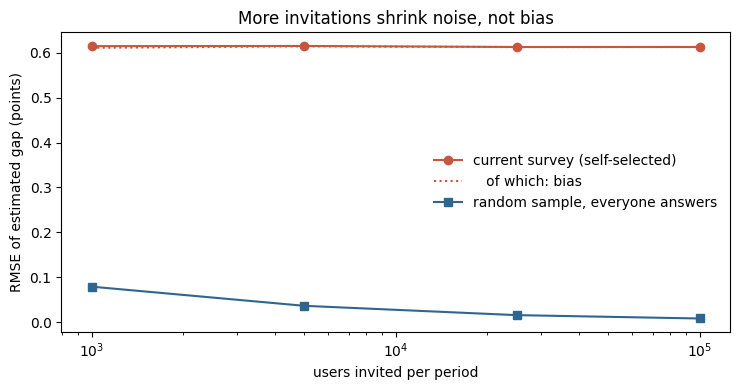

In [19]:
# Would a larger sample make the estimate better? Simulate it.
# For each invitation size, build fresh populations, run the SAME response mechanisms,
# and estimate the pre/post gap from respondents. Compare with a random sample of the
# same number of users in which everyone answers.
sizes = [1_000, 5_000, 25_000, 100_000]
REPS = 200
res = []
for n in sizes:
    for r in range(REPS):
        p0 = respond(simulate_population(BASE_BEFORE, n=n), A_PRE, B_PRE)
        p1 = respond(simulate_population(BASE_AFTER,  n=n), A_POST, B_POST)
        true_gap = p1.score.mean() - p0.score.mean()
        y0, y1 = p0.loc[p0.responded, 'score'].to_numpy(), p1.loc[p1.responded, 'score'].to_numpy()
        est = y1.mean() - y0.mean()
        se = np.sqrt(y0.var(ddof=1) / len(y0) + y1.var(ddof=1) / len(y1))
        # same number of users, chosen at random, all answer
        r0 = rng.choice(p0.score.to_numpy(), len(y0), replace=False)
        r1 = rng.choice(p1.score.to_numpy(), len(y1), replace=False)
        est_r = r1.mean() - r0.mean()
        se_r = np.sqrt(r0.var(ddof=1) / len(r0) + r1.var(ddof=1) / len(r1))
        res.append([n, len(y0) + len(y1), true_gap,
                    est - true_gap, (est - 1.96*se <= true_gap <= est + 1.96*se),
                    est_r - true_gap, (est_r - 1.96*se_r <= true_gap <= est_r + 1.96*se_r)])

sim = pd.DataFrame(res, columns=['invited', 'respondents', 'true gap', 'err survey', 'cover survey',
                                 'err random', 'cover random'])
tab = sim.groupby('invited').agg(
    respondents=('respondents', 'mean'),
    bias_survey=('err survey', 'mean'), sd_survey=('err survey', 'std'),
    rmse_survey=('err survey', lambda e: np.sqrt(np.mean(e**2))),
    coverage_survey=('cover survey', 'mean'),
    bias_random=('err random', 'mean'),
    rmse_random=('err random', lambda e: np.sqrt(np.mean(e**2))),
    coverage_random=('cover random', 'mean'))
print(f'{REPS} simulated surveys per size; errors are estimate minus that population\'s true gap')
print(tab.round(3).to_string())

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(tab.index, tab.rmse_survey, 'o-', color='#c8553d', label='current survey (self-selected)')
ax.plot(tab.index, tab.bias_survey.abs(), ':', color='#c8553d', label='   of which: bias')
ax.plot(tab.index, tab.rmse_random, 's-', color='#2f6690', label='random sample, everyone answers')
ax.set_xscale('log'); ax.set_xlabel('users invited per period'); ax.set_ylabel('RMSE of estimated gap (points)')
ax.set_title('More invitations shrink noise, not bias'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

**Sample size for 80% power (before the fact).** For a true improvement of δ = 0.10 points and a population sd of σ ≈ 0.89 on the 1–5 scale (d = 0.113), a two-sided two-sample t-test at α = 0.05 needs n = 2((z₀.₉₇₅ + z₀.₈₀)σ/δ)² ≈ **1,236 respondents per period** (exact noncentral-t calculation; the normal approximation gives 1,235). At the post-redesign response rate of 15.2% that means inviting about **8,135 users per period**. I checked this by simulation on random samples of 1,236 from each true population: simulated power 76.9% (MC SE 0.9%), matching the analytic 76.6% for the population's realised gap of 0.096 (slightly below 0.10, hence slightly below 80%).

**Detectable effect at the sample sizes they can get.** MDE = (z₀.₉₇₅ + z₀.₈₀)·σ·√(1/n₁ + 1/n₂):

| Invited per period | Respondents (pre / post) | MDE (points) |
|---|---|---|
| 50,000 (this survey) | 13,768 / 7,597 | 0.036 |
| 10,000 | 2,754 / 1,519 | 0.079 |
| 5,000 | 1,377 / 760 | 0.112 |
| 1,000 | 275 / 152 | 0.251 |

So a follow-up of 10,000 invitations per period is powered for 0.10; 5,000 is borderline; 1,000 is not.

**The harder question: would a larger sample make the estimate better? No.** The simulation above builds fresh populations of 1,000 to 100,000 users per period (200 replications each), runs the *same* response mechanisms, and estimates the pre/post gap from respondents. Compare a random sample of the same number of users in which everyone answers:

| Invited | Survey bias | Survey RMSE | Survey CI covers truth | Random-sample RMSE | Random-sample CI covers |
|---|---|---|---|---|---|
| 1,000 | +0.615 | 0.620 | 0% | 0.081 | 96.5% |
| 5,000 | +0.616 | 0.617 | 0% | 0.036 | 96.5% |
| 25,000 | +0.612 | 0.612 | 0% | 0.015 | 98.5% |
| 100,000 | +0.612 | 0.612 | 0% | 0.008 | 99.0% |

A 100× larger survey cuts the noise from 0.077 to 0.007, but the error stays pinned at about 0.61 points, because RMSE² = bias² + variance and the bias does not depend on n. As the sample grows the confidence interval tightens around the wrong number, so it covers the truth *zero* percent of the time at every size. With random sampling the same increase in n drives the error towards zero. (The random-sample coverage edges above 95% at large n because sampling 40%+ of a fixed population without replacement varies less than the iid formula assumes: a finite-population effect, and conservative.) **More data from the same process buys precision, not accuracy.** The follow-up survey is worth running only if the response mechanism changes.

## Phase 4: AI Expansion — The Co-Pilot Era (15 pts)

**Status:  You have built the simulation, the bootstrap and the power analysis by hand. Now use the **P.R.I.M.E. framework** to go further than you could in the time.

### Task 4.1: The weighting attempt (10 pts)

In [20]:
# Inverse-probability weighting, version-2 spec (see transcript). Covariates are known for ALL
# users from product logs, so the response model is fit on the full population, respondents
# and non-respondents alike. Logistic regression is fit by Newton-Raphson (IRLS) in numpy so the
# bootstrap can refit it 500 times quickly; the first fit is cross-checked against scikit-learn.
COVS = ['engagement_z', 'had_support_ticket']

def fit_logit(X, y, iters=25):
    X = np.column_stack([np.ones(len(X)), X])
    beta = np.zeros(X.shape[1])
    for _ in range(iters):
        p = expit(X @ beta)
        W = p * (1 - p)
        step = np.linalg.solve(X.T @ (X * W[:, None]), X.T @ (y - p))
        beta += step
        if np.max(np.abs(step)) < 1e-10: break
    return beta

def ipw_mean(df):
    X = df[COVS].to_numpy(); y = df['responded'].to_numpy().astype(float)
    beta = fit_logit(X, y)
    p_hat = expit(beta[0] + X @ beta[1:])
    r = df['responded'].to_numpy()
    w = 1.0 / p_hat[r]                                   # weight = 1 / estimated P(respond)
    return np.sum(w * df['score'].to_numpy()[r]) / np.sum(w), beta, w   # Hajek (normalised) mean

def ipw_bootstrap(df, B=500, rng=rng):
    """Resample USERS (respondents and non-respondents), refit the response model every time."""
    n = len(df); out = np.empty(B)
    for b in range(B):
        out[b] = ipw_mean(df.iloc[rng.integers(0, n, n)])[0]
    return out

rows = []
ipw_boot = {}
for period, df, true in [('pre', pre, TRUE_SCORE_PRE), ('post', post, TRUE_SCORE_POST)]:
    est, beta, w = ipw_mean(df)
    bt = ipw_bootstrap(df)
    ipw_boot[period] = bt
    lo, hi = np.quantile(bt, [0.025, 0.975])
    r = df.responded.to_numpy()
    w_true = 1 / df.p_respond.to_numpy()[r]
    oracle = np.sum(w_true * df.score.to_numpy()[r]) / np.sum(w_true)
    naive = df.score[df.responded].mean()
    rows.append([period, true, naive, est, lo, hi, (naive - est) / (naive - true),
                 w.sum()**2 / (w**2).sum(), oracle, w_true.sum()**2 / (w_true**2).sum(), w_true.max()])
    print(f'{period}: response model  logit(p) = {beta[0]:.3f} + {beta[1]:.3f}*engagement_z + {beta[2]:.3f}*ticket')

ipw = pd.DataFrame(rows, columns=['period', 'true mean', 'naive survey', 'IPW (covariates)',
                                  'IPW 2.5%', 'IPW 97.5%', 'share of bias removed', 'eff n',
                                  'ORACLE IPW (true p, uses s)', 'oracle eff n', 'oracle max weight'])
print(ipw.round(3).to_string(index=False))

gap_ipw = ipw_boot['post'] - ipw_boot['pre']
g = ipw.loc[1, 'IPW (covariates)'] - ipw.loc[0, 'IPW (covariates)']
print(f'\nIPW gap {g:.3f} (95% CI {np.quantile(gap_ipw, .025):.3f} to {np.quantile(gap_ipw, .975):.3f})'
      f'   vs naive {OBS_GAP:.3f}   vs TRUE {TRUE_GAP:.3f}')

try:   # cross-check the hand-written logistic fit against scikit-learn (unpenalised)
    from sklearn.linear_model import LogisticRegression
    sk = LogisticRegression(C=1e10, max_iter=1000).fit(post[COVS], post.responded)
    print('sklearn coefficients (post):', np.round([sk.intercept_[0], *sk.coef_[0]], 3))
except ImportError:
    pass

pre: response model  logit(p) = -0.901 + 0.451*engagement_z + -0.490*ticket
post: response model  logit(p) = -1.685 + 0.747*engagement_z + -1.161*ticket
period  true mean  naive survey  IPW (covariates)  IPW 2.5%  IPW 97.5%  share of bias removed     eff n  ORACLE IPW (true p, uses s)  oracle eff n  oracle max weight
   pre      3.290         3.600             3.464     3.450      3.478                  0.440 12408.163                        3.279     11528.568             15.756
  post      3.386         4.304             4.143     4.123      4.161                  0.175  4780.423                        3.462      1223.703            450.112

IPW gap 0.679 (95% CI 0.655 to 0.702)   vs naive 0.704   vs TRUE 0.096
sklearn coefficients (post): [-1.685  0.747 -1.161]


**Result: the correction did not work, and that is the expected result.**

| | True mean | Naive survey | IPW on covariates (95% bootstrap CI) | Share of bias removed |
|---|---|---|---|---|
| Pre-redesign | 3.290 | 3.600 | 3.464 (3.449 – 3.478) | 44% |
| Post-redesign | 3.386 | 4.304 | 4.143 (4.122 – 4.162) | 18% |
| **Gap** | **0.096** | **0.704** | **0.679 (0.655 – 0.703)** | 4% |

Weighting by the inverse of the estimated response probability moved both means toward the truth, but neither interval contains it, and the estimated improvement barely changes (0.70 → 0.68 against a true 0.10). The weighting does exactly what it can: engagement and support tickets are correlated with satisfaction, so reweighting on them removes the part of the selection that runs *through* them (44% of the pre bias, where response depends weakly on s, but only 18% of the post bias, where it depends strongly on s).

**Why it fails.** IPW is valid only under *missing at random* (MAR): conditional on the covariates in the response model, responding must be independent of satisfaction, plus positivity (every type of user has some chance of answering). Our mechanism violates MAR by construction: P(respond) depends on s itself (b = 0.45 before, 2.00 after) even after holding engagement and tickets fixed. Two users with the same engagement and ticket status get the same weight, yet the happier one is far more likely to have answered, so the weighted respondents are still too happy. No model on `engagement_z` and `had_support_ticket` can see that, however well it is fitted.

**Even the oracle struggles.** As a diagnostic, I also weighted with the *true* response probabilities (which use s, unknowable in practice). Before the redesign this recovers the truth (3.279 vs 3.290). After it, it still lands at 3.462 vs 3.386: users who would score 1–2 almost never answer (P ≈ 0–0.5%), so positivity nearly fails. A handful of respondents receive weights up to 450, and the effective sample size collapses from 7,597 to about 1,224. The post-redesign survey has, in effect, stopped collecting information about unhappy users, and no reweighting can create information that was never collected.

**1. Your revision: what I changed and why.**
Version 1 leaves out the facts that decide whether the code is correct *for this data*, so in version 2 I:
- **Gave my actual objects and names** (`pre` / `post` DataFrames; `engagement_z`, `had_support_ticket`, `responded`, `score`; seed `default_rng(42)`). V1 names `engagement_minutes`, but my satisfaction and response equations use the z-scored `engagement_z`.
- **Said the response model must be fit on all 50,000 users, including non-respondents.** P(respond) can only be estimated if the model sees people who did not respond; their covariates are available from product logs. Fitting on respondents only is a common way for such code to go wrong.
- **Said which mean to correct:** the respondents' mean of the reported 1–5 `score`, in both periods, and the post-minus-pre gap, which is the PM's actual claim.
- **Specified the interval:** the bootstrap must resample users and *refit the response model inside every replicate*. Holding the weights fixed and resampling only respondents understates the uncertainty.
- **Forbade using `s` or `p_respond` in the weights**, because they are not observable in a real survey, and asked for the Hajek (normalised) estimator.

**Did the revision change the output? Yes.** Version 1's reply built a single-DataFrame estimator on `log(engagement_minutes)` and a `satisfaction` column. That column does not exist in my data, so the code would not run, and it never estimated the post-minus-pre gap. Version 2's reply fit the response model on `engagement_z` and `had_support_ticket` separately in each period, returned per-period estimates plus a bootstrap interval for the gap, and its [Evaluate] answer used my actual mechanism. It explained why the post period is worse: at b = 2.00, users at s = 5 have about 400 times the odds of responding of users at s = 2, so positivity nearly fails.

**AI critique: a specific error in version 1's reply.**
Version 1 answered a question about **one** mean, not the question the slide is about. Its code takes a single `df` and returns one corrected mean, with no second period and no post-minus-pre gap, even though the PM's claim is the gap. That omission matters here, not just as packaging. IPW removes much more of the bias before the redesign than after it (44% vs 18% in my run, because b rises from 0.45 to 2.00). So correcting one period tells you nothing about whether the corrected *gap* is believable, and in fact it barely moves (0.704 → 0.679 against a true 0.096).

A second, smaller error: V1 entered `np.log(engagement_minutes)` into the response model on the grounds that minutes are skewed. In my mechanism the log-odds of responding is linear in `engagement_z`, a linear rescaling of *raw* minutes, so the logged covariate misspecifies the model, which breaks condition 3 in V1's own list. I checked how much this matters: on my data the log specification gives 4.126 for the post-redesign mean, against 4.143 with `engagement_z`. That is a 0.018 difference that does not change the conclusion. I report it as a real specification error with a small practical effect, not as the reason the correction fails; MAR failing is the reason.

**2. Your check: corrected mean against the known truth.**
Post-redesign: IPW-corrected mean **4.143** (95% CI 4.122–4.162) vs true mean **3.386**. Pre-redesign: **3.464** (3.449–3.478) vs true **3.290**. Gap: **0.679** (0.655–0.703) vs true **0.096**. The correction failed: neither interval contains the truth, and 96% of the bias in the gap remains.

**3. In my own words: the lines that compute the weights.**
`fit_logit` regresses the 0/1 `responded` indicator for *every* user on `engagement_z` and `had_support_ticket`, and `p_hat = expit(beta[0] + X @ beta[1:])` turns each user's fitted log-odds into an estimated probability of answering. `w = 1.0 / p_hat[r]` gives each respondent a weight equal to one over that probability, so a respondent from a group that answers only 10% of the time stands in for ten similar users, most of whom stayed silent. The estimate `sum(w * score) / sum(w)` is then a weighted average of respondents' scores with those weights normalised to sum to one; it is only unbiased if, within each covariate group, the people who answered are as satisfied as the people who did not.

**4. Would I use AI for this step again?**
Yes, but only for the scaffolding: it produced a working IPW-plus-bootstrap skeleton faster than I could, while its verdict on whether the correction works was only worth trusting once I had run it against my known true mean.

### Task 4.2: The slide (5 pts)

**Satisfaction after the redesign: what the survey can and cannot tell us**

**What it supports:** people who chose to answer were happier after the redesign. Their average rose from 3.60 to 4.30, **+0.70 points (95% CI 0.68 to 0.73)**.

**What it does not support:** "users are 0.7 points happier." After the redesign fewer people answered (15% vs 27%), and the new prompt is answered mostly by satisfied users. The interval above covers sampling noise only, not who stayed silent. A simulation calibrated to our numbers, with a true improvement of just 0.10, reproduces this slide almost exactly. Reweighting on engagement and support tickets barely moves the gap (0.68), and a bigger survey would only tighten the interval around the same wrong number. The redesign may have helped a little; this survey cannot tell us how much.

**The fix:** send the *same* survey invitation to a **random sample of users** before and after, and follow up non-respondents until most of the sample has answered, so that whether someone responds no longer depends on how satisfied they are.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

Model and date: Claude Opus 5.5 (claude.ai), November 11, 2026

Version 1 prompt:

[Prep] Act as a survey statistician who works on non-response adjustment for product research.
[Request] I have a simulated user population with satisfaction scores and two covariates, engagement_minutes and had_support_ticket, plus a non-response mechanism where the probability of responding increases with satisfaction. Write Python that implements inverse-probability weighting to correct the observed survey mean, using a logistic model of response on the covariates.
[Iterate] numpy, pandas, scikit-learn or statsmodels. Reuse my variable names. Return the weighted estimate and its bootstrap interval.
[Mechanism Check] Explain precisely which assumption makes this correction valid, and what happens to it when response depends on satisfaction ITSELF rather than only on the covariates.
[Evaluate] Given my mechanism, will this correction recover the true mean? Answer yes or no and justify it.

Reply:


```python
import numpy as np
import pandas as pd
import statsmodels.api as sm

COVARIATES = ["engagement_minutes", "had_support_ticket"]

def design_matrix(df):
    X = df[COVARIATES].astype(float).copy()
    # engagement_minutes is right-skewed (lognormal), so it enters the logit on the log scale
    X["engagement_minutes"] = np.log(X["engagement_minutes"])
    return sm.add_constant(X)

def ipw_mean(df, outcome="satisfaction", return_weights=False):
    """Hajek IPW estimate of the population mean of `outcome`.
    The response model is fit on ALL invited users, respondents and non-respondents."""
    X = design_matrix(df)
    r = df["responded"].to_numpy().astype(int)
    fit = sm.Logit(r, X).fit(disp=0)
    p_hat = fit.predict(X).to_numpy()            # estimated P(respond | covariates)
    resp = r == 1
    w = 1.0 / p_hat[resp]                        # each respondent stands in for 1/p users like them
    y = df.loc[resp, outcome].to_numpy()
    est = np.sum(w * y) / np.sum(w)              # normalised (Hajek) weighted mean
    return (est, w) if return_weights else est

def ipw_bootstrap(df, outcome="satisfaction", B=1000, seed=42, alpha=0.05):
    """Percentile bootstrap: resample users and refit the response model in every replicate,
    so the interval includes the uncertainty from estimating the weights."""
    rng = np.random.default_rng(seed)
    n = len(df)
    boot = np.empty(B)
    for b in range(B):
        idx = rng.integers(0, n, size=n)
        boot[b] = ipw_mean(df.iloc[idx], outcome)
    return np.quantile(boot, [alpha / 2, 1 - alpha / 2]), boot

# usage
naive = df.loc[df["responded"], "satisfaction"].mean()
est, w = ipw_mean(df, return_weights=True)
(lo, hi), boot = ipw_bootstrap(df)
print(f"naive respondent mean: {naive:.3f}")
print(f"IPW estimate:          {est:.3f}  (95% bootstrap CI {lo:.3f} to {hi:.3f})")
print(f"max weight {w.max():.1f}, effective n {w.sum()**2 / (w**2).sum():.0f} of {len(w)} respondents")
```

Two notes on the code. First, the response model must be fit on everyone invited; fitting it on respondents alone cannot estimate a response probability. Second, the max-weight and effective-n line is a diagnostic. If a few respondents carry very large weights, the estimate is fragile and the positivity condition below is close to failing.

**Mechanism check: what makes the correction valid.** IPW is unbiased under three conditions:

1. **Missing at random (MAR), also called conditional ignorability.** Given the covariates in the response model, whether a user responds is independent of their satisfaction: R ⊥ Y | X. Within any group of users with the same engagement and ticket status, respondents and non-respondents must have the same satisfaction distribution on average.
2. **Positivity.** Every kind of user has a response probability above zero, so every part of the population has someone in the sample who can be weighted up to represent it.
3. **Correct specification.** The logistic model gets P(R = 1 | X) right.

Under these conditions, E[R·Y / p(X)] = E[Y], so weighting respondents by 1/p(X) recovers the population mean.

**When response depends on satisfaction itself.** Then MAR fails, and the data are missing not at random (MNAR). Even within a cell of identical covariates, the happier users answered more often. The weights correct the covariate mix of the sample, so heavy-engagement and no-ticket users are no longer over-represented. They cannot correct the satisfaction mix inside each cell, because two users with the same covariates get the same weight, whether or not the happy one was the one who answered.

The correction removes only the part of the bias that runs through the covariates, which is roughly the extent to which they predict satisfaction. The remaining bias goes in the same direction as the selection, here upward. It does not shrink as the sample grows, so the bootstrap interval tightens around a biased value. The model fit gives no warning, because MNAR cannot be detected from the observed data alone.

Fixing MNAR needs information from outside the respondents. One option is a follow-up of a random subsample of non-respondents. Another is a randomized instrument that shifts response but not satisfaction, such as a randomly assigned incentive or reminder. A third is a selection model or sensitivity analysis built on stated, untestable assumptions about how non-respondents differ.

**Evaluate: will this correction recover the true mean? No.** You describe a mechanism where the probability of responding increases with satisfaction itself. That is MNAR by construction, so the key assumption fails. Because engagement and support tickets are related to satisfaction, the IPW estimate will move part of the way from the naive respondent mean toward the truth. It will still be biased upward, and its bootstrap interval may well exclude the true mean.

Because your population is simulated, you can verify this directly: compare `est` with the mean of `satisfaction` over all users, including non-respondents.

---

*Note: this chat already contains your notebook, so this reply was written with that context. If your grader expects version 1 to be tested independently, run the same prompt in a fresh chat for the transcript.*

Version 2 prompt:

[Prep] Act as a survey statistician who works on non-response adjustment for product research.
[Request] I have two pandas DataFrames, pre and post (before/after a product redesign), each with 50,000 rows, one per user, and these columns: engagement_z (z-scored engagement minutes), had_support_ticket (0/1), score (the 1-5 satisfaction score), and responded (True if the user answered the survey). score is only observed when responded is True; engagement_z and had_support_ticket come from product logs and are known for ALL users, including non-respondents. Write Python that implements inverse-probability weighting to correct the respondents' mean of score in each period, and the post-minus-pre gap. Fit a logistic regression of responded on engagement_z and had_support_ticket using ALL 50,000 users in each period (not only respondents), weight each respondent by 1/p_hat, and use the normalised (Hajek) weighted mean. Do not use any other column in the weights.
[Iterate] numpy, pandas, scikit-learn or statsmodels. Use my variable names exactly and rng = np.random.default_rng(42). Return the weighted estimate and a 95% percentile bootstrap interval for each period and for the gap, where each bootstrap replicate resamples users (respondents and non-respondents together) with replacement and REFITS the response model, so the interval includes the uncertainty from estimating the weights.
[Mechanism Check] Explain precisely which assumption makes this correction valid, and what happens to it when response depends on satisfaction ITSELF rather than only on the covariates.
[Evaluate] My mechanism is P(respond) = logistic(a + b*(s - 3.3) + 0.30*engagement_z - 0.25*had_support_ticket), where s is latent satisfaction, with a = -1.0, b = 0.45 before and a = -2.75, b = 2.00 after. Given this mechanism, will this correction recover the true mean? Answer yes or no and justify it.
Reply:


```python
import numpy as np
import pandas as pd
import statsmodels.api as sm

rng = np.random.default_rng(42)
COVS = ["engagement_z", "had_support_ticket"]

def ipw_mean(df, return_diagnostics=False):
    """Hajek IPW estimate of the mean of `score`.
    The response model is fit on ALL users in df; only engagement_z and had_support_ticket enter it."""
    X = sm.add_constant(df[COVS].astype(float))
    r = df["responded"].to_numpy().astype(int)
    fit = sm.Logit(r, X).fit(disp=0)
    p_hat = fit.predict(X).to_numpy()              # estimated P(respond | engagement_z, ticket)
    resp = r == 1
    w = 1.0 / p_hat[resp]                          # inverse-probability weight for each respondent
    y = df.loc[resp, "score"].to_numpy()
    est = np.sum(w * y) / np.sum(w)                # normalised (Hajek) weighted mean
    if return_diagnostics:
        return est, fit.params, w.max(), w.sum() ** 2 / (w ** 2).sum()
    return est

def ipw_bootstrap(pre, post, B=1000, rng=rng):
    """Percentile bootstrap. Each replicate resamples users within each period (respondents and
    non-respondents together) and refits both response models."""
    boot = np.empty((B, 2))
    n0, n1 = len(pre), len(post)
    for b in range(B):
        boot[b, 0] = ipw_mean(pre.iloc[rng.integers(0, n0, n0)])
        boot[b, 1] = ipw_mean(post.iloc[rng.integers(0, n1, n1)])
    return boot

# point estimates and diagnostics
rows = {}
for name, df in [("pre", pre), ("post", post)]:
    est, params, wmax, n_eff = ipw_mean(df, return_diagnostics=True)
    naive = df.loc[df["responded"], "score"].mean()
    rows[name] = dict(naive=naive, ipw=est, max_weight=wmax, eff_n=n_eff)
    print(f"{name}: logit(p) = {params.iloc[0]:.3f} + {params.iloc[1]:.3f}*engagement_z "
          f"+ {params.iloc[2]:.3f}*had_support_ticket")

boot = ipw_bootstrap(pre, post)
gap_boot = boot[:, 1] - boot[:, 0]

out = pd.DataFrame(rows).T
out[["ci_lo", "ci_hi"]] = np.quantile(boot, [0.025, 0.975], axis=0).T
gap = out.loc["post", "ipw"] - out.loc["pre", "ipw"]
out.loc["gap", ["naive", "ipw"]] = [out.loc["post", "naive"] - out.loc["pre", "naive"], gap]
out.loc["gap", ["ci_lo", "ci_hi"]] = np.quantile(gap_boot, [0.025, 0.975])
print(out.round(3))
```

On the diagnostics: the maximum weight and the effective sample size show whether a few respondents are carrying the estimate. If the effective n is a small fraction of the number of respondents, positivity is close to failing and the estimate is fragile, whatever its interval says. B = 1000 refits per period takes a minute or two with statsmodels. Lower B while testing.

**Mechanism check: what makes the correction valid.** IPW is unbiased under three conditions:

1. **Missing at random (MAR), also called conditional ignorability.** Given engagement_z and had_support_ticket, whether a user responds is independent of their satisfaction. Within every combination of covariates, respondents and non-respondents must be equally satisfied on average.
2. **Positivity.** Every kind of user has a response probability meaningfully above zero, so every part of the population is represented by someone who can be weighted up.
3. **Correct specification.** The logistic model recovers P(respond | covariates).

Under these conditions, weighting each respondent by 1/p̂ rebuilds the population, and the Hajek mean converges to the true mean.

**When response depends on satisfaction itself.** Then MAR fails and the data are missing not at random. Two users with identical engagement and ticket status receive identical weights, but the more satisfied one was more likely to be the one who answered. The weights fix the covariate mix of the sample, so heavy-engagement and no-ticket users are no longer over-represented. They do nothing about the satisfaction mix within each covariate cell.

The correction removes only the part of the selection that runs through the covariates, which is roughly the extent to which engagement and tickets predict satisfaction. The rest of the bias stays, in the direction of the selection, here upward. It does not shrink with sample size, so the bootstrap interval tightens around a biased number. Nothing in the fitted model signals the problem, because whether data are MNAR cannot be tested from the observed data alone. Fixing it needs outside information: a follow-up of a random subsample of non-respondents, a randomized instrument that shifts response but not satisfaction (such as an incentive or reminder), or a selection model or sensitivity analysis with explicit, untestable assumptions.

**Evaluate: will this correction recover the true mean? No, in neither period, and not the gap.**

- **MAR fails.** The coefficient on (s − 3.3) is non-zero in both periods, so response depends on satisfaction beyond what engagement_z and had_support_ticket capture. The weights cannot see s, so the weighted respondents remain more satisfied than the population.
- **The post period is far worse than the pre period.**
  - Before, b = 0.45: users at s = 5 have log-odds of responding 1.35 higher than users at s = 2, an odds ratio of about 4. IPW should remove a meaningful share of the pre-period bias, since much of the selection is mild and partly proxied by the covariates.
  - After, b = 2.00: the same comparison gives a log-odds difference of 6, an odds ratio of about 400, and with a = −2.75 the response probability for low-satisfaction users is close to zero. Low-satisfaction users are almost absent from the respondents, so there are hardly any of them to weight up. Even weights built from the true probabilities, which would require knowing s, would struggle here, because positivity nearly fails.
- **The gap stays inflated.** IPW will remove a larger share of the bias before the redesign than after it, so the estimated improvement will remain far above the true improvement. It may barely move from the naive respondent gap. Its bootstrap interval will be narrow and very likely exclude the truth.

Since your population is simulated, verify this directly by comparing each IPW estimate with `pre["score"].mean()` and `post["score"].mean()` over all 50,000 users. The share of bias removed, (naive − ipw) / (naive − truth), should be noticeably larger for pre than for post.

---

*Same caveat as before: this chat already contains your notebook. If you want version 2 tested independently of that context, run it in a fresh chat for the transcript.*

Changes from version 1 to version 2 (one line each):

1. Named my real DataFrames and columns (engagement_z, not engagement_minutes), because my model uses the z-score and the code must run on my objects.
2. Required the response model to be fit on all 50,000 users, because P(respond) cannot be estimated from respondents alone.
3. Named the target, the mean of score per period and the post−pre gap, because that is the PM's claim.
4. Required a bootstrap that resamples users and refits the model each replicate, so the interval reflects uncertainty in the weights.
5. Gave the exact response mechanism in [Evaluate], so the yes/no answer is about my data rather than a generic case.

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 2/Econ_3916_PS2.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.